# Dichotic (left + right together)

Part of the per-condition split of `cortical_analysis.ipynb`; runs on its own.
Both dichotic halves pooled (the `dichotic` epoch: ignored speaker on the left and on the right),
to compare with `dichotic_left.ipynb` and `dichotic_right.ipynb`.
Shared settings (models, fit parameters, ROI, peak windows, plot window) are in
`parameters.py`.

**Results come from the cluster.** Every fit and model test is computed and kept on the
cluster; this notebook only reads them and saves nothing. In the cluster's JupyterHub
(any browser, laptop closed) it reads them from the cluster's disk; on the Mac (VS Code or
Jupyter), open the connection once in a terminal with `bash cluster/connect.sh`. The
`check_results` cell below asks the cluster for anything missing by itself, waits for the job
and then carries on, so one Run All goes from start to finish (keep the computer awake). See `cluster/README.md`.

**Model comparisons:** TFCE permutation tests within the ROI found in the clean notebook
(`roi.txt`, read by the `check_results` cell; `TEST_REGION` in `parameters.py`), as
Brodbeck et al. 2020 did for the two-talker conditions.

**Peaks:** each subject's peak is searched within +-25 ms of where that condition's
group-average waveform peaks inside the search window (`add_anchored_peak`).

**Per-bin TRF plots** (`plot_trf_bins`): one line per frequency bin in its own colour
with a band of +-1 SEM across subjects (`BIN_ERROR` in `parameters.py`), the mean of
the bins as the thick black line, and the bins' centre frequencies on the right.

In [1]:
from parameters import *

In [2]:
# Checks that every result this notebook reads is on the cluster. If any are missing it
# asks the cluster for them, waits for the job (a line whenever its state changes) and
# carries on. Keep the computer awake while it waits.
check_results('dichotic')

10 of 11 results this notebook reads are not on the cluster yet; job 9568403 is already computing them.
Waiting for job 9568403 (checked every minute; the cluster also emails when it ends). Interrupting only stops the waiting, not the job.
  20:23  9568403 running  (0 min so far)
ROI from the clean notebook (18 sensors): AF3, F1, F3, F5, F7, FC5, FC3, C1, C3, C5, AF4, AFz, F6, FT8, FC6, FC4, FC2, C2
Job 9568403 is done: all 11 results are on the cluster. Carrying on with the notebook.


In [3]:
# Your cluster jobs (PD = waiting for a slot, R = running).
cluster_queue()

          JOBID     USER      ACCOUNT           NAME  ST  TIME_LEFT NODES CPUS TRES_PER_N MIN_MEM NODELIST (REASON) 
        9570811     iggy def-ibruce_c cocktail-dicho   R 1-19:42:39     1   32        N/A    128G nc30642 (None) 



In [4]:
# The end of the latest cluster job's log (or cluster_log(<job number>)).
cluster_log()

== cocktail-dichotic-9568403.out
INFO    :  *** BinauralCocktail initialized with root /lustre06/project/6005583/iggy/dataset/cocktail/bids on 2026-11-16 20:04:03 ***
INFO    :  Using eelbrain 0.0.0, mne 1.13.2.
INFO    :  *** BinauralCocktail initialized with root /lustre06/project/6005583/iggy/dataset/cocktail/bids on 2026-11-16 20:04:50 ***
INFO    :  Using eelbrain 0.0.0, mne 1.13.2.
  bad-channels file already exists for: 01, 02, 03, 04, 05, 06, 07, 08, 09, 10, 11, 12, 13. Skip all of them (default) or redo and overwrite all of them? [s/r]: s  (COCKTAIL_ANSWER)
  skipping (already done): 01, 02, 03, 04, 05, 06, 07, 08, 09, 10, 11, 12, 13

Done. Bad channels marked.
  ICA file already exists for: 01, 02, 03, 04, 05, 06, 07, 08, 09, 10, 11, 12, 13. Skip all of them (default) or redo and overwrite all of them? [s/r]: s  (COCKTAIL_ANSWER)
  skipping (already done): 01, 02, 03, 04, 05, 06, 07, 08, 09, 10, 11, 12, 13

Done. ICA fit and artifact components selected.
=== dichotic  2026-11

## Dichotic (left + right)

In [5]:
# The ROI this notebook uses, imported from roi.txt: the clean-speech notebook found it
# from its onset and envelope test - baseline topomaps.
ROI = show_roi('dichotic')

ROI imported from roi.txt (~/projects/def-ibruce/iggy/dataset/cocktail/bids/derivatives/results/roi.txt), determined by the clean-speech notebook from its onset and envelope test - baseline topomaps (conjunction: significant for every predictor).
Used for every ROI test, STRF, TRF waveform and peak below.

ROI (18 sensors): AF3, F1, F3, F5, F7, FC5, FC3, C1, C3, C5, AF4, AFz, F6, FT8, FC6, FC4, FC2, C2


In [6]:
# Loaded once here, reused by every unique-contribution/STRF/peak/
# waveform/attention-effect cell in this section - each one just
# reads a different predictor column out of this same fit instead
# of re-running the (expensive) TRF fit on FULL_BASE again.
data_full = load_trfs_saved(FULL_BASE, 'dichotic')

<small>

**Stream-level tests: each stream's envelope + onsets removed together**

- A stream = one talker's (or the mixture's) envelope + onsets
- Asks whether the brain tracks that stream at all, beyond the other two
- Can be significant when neither the envelope nor the onsets alone are

</small>

Permutation test:   0%|          | 0/8191 [00:00<?, ? permutations/s]

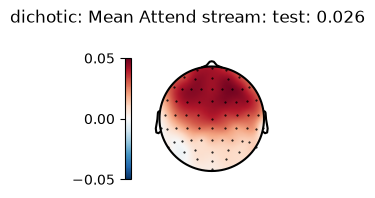

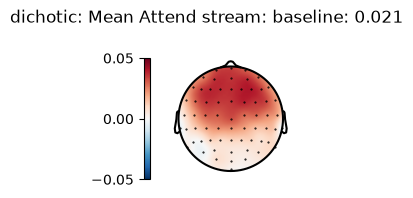

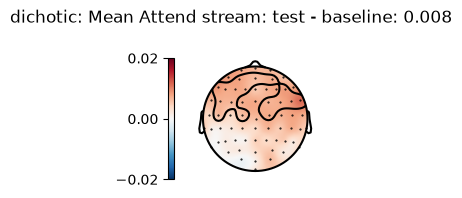

In [7]:
# Attend stream (envelope + onsets) unique contribution (dichotic)
data, diff, result = compute_direct_comparison(FULL_BASE, FULL_BASE_NO_ATTEND_STREAM, 'dichotic')
show_topomap_trio(data, diff, result, 'Attend stream', 'dichotic', None)

In [8]:
display(result)
print(f"Attend stream (dichotic): TFCE {tfce_summary(result)}")
ttest = test.TTestOneSample(f'roi_{METRIC}', data=diff, tail=1)
print(f"Attend stream (dichotic): ROI model comparison t({ttest.df}) = {ttest.t:.3f}, p = {ttest.p:.4f}")

<TTestRelated 'r', 'model', 'test', 'baseline', 'subject' (n=13), tail=1, samples=8191, tfce=True, p = .002>

Attend stream (dichotic): TFCE t_max = 4.19, p = 0.002
Attend stream (dichotic): ROI model comparison t(12) = 3.056, p = 0.0050


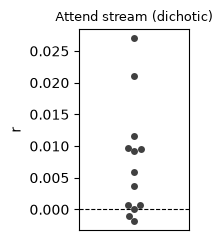

In [9]:
p = show_subject_swarm(diff, 'Attend stream', 'dichotic')

Permutation test:   0%|          | 0/8191 [00:00<?, ? permutations/s]

/Users/joshuaighalo/Github Repositories/cocktail-cortical/analysis/experiment.py:1063: UserWarning: Warning: converting a masked element to nan.
  mean_value = float(data.mean())


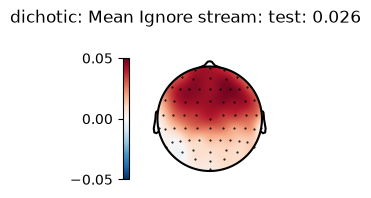

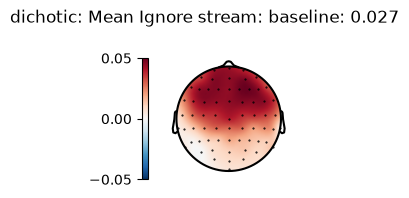

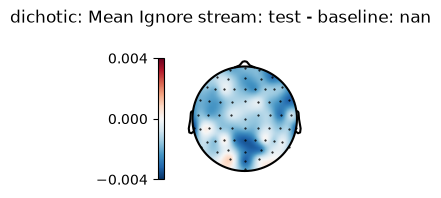

In [10]:
# Ignore stream (envelope + onsets) unique contribution (dichotic)
data, diff, result = compute_direct_comparison(FULL_BASE, FULL_BASE_NO_IGNORE_STREAM, 'dichotic')
show_topomap_trio(data, diff, result, 'Ignore stream', 'dichotic', None)

In [11]:
display(result)
print(f"Ignore stream (dichotic): TFCE {tfce_summary(result)}")
ttest = test.TTestOneSample(f'roi_{METRIC}', data=diff, tail=1)
print(f"Ignore stream (dichotic): ROI model comparison t({ttest.df}) = {ttest.t:.3f}, p = {ttest.p:.4f}")

<TTestRelated 'r', 'model', 'test', 'baseline', 'subject' (n=13), tail=1, samples=8191, tfce=True, p = 1.000>

Ignore stream (dichotic): TFCE t_max = -0.32, p = 1.000
Ignore stream (dichotic): ROI model comparison t(12) = -2.539, p = 0.9870


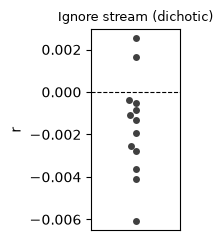

In [12]:
p = show_subject_swarm(diff, 'Ignore stream', 'dichotic')

Permutation test:   0%|          | 0/8191 [00:00<?, ? permutations/s]

/Users/joshuaighalo/Github Repositories/cocktail-cortical/analysis/experiment.py:1063: UserWarning: Warning: converting a masked element to nan.
  mean_value = float(data.mean())


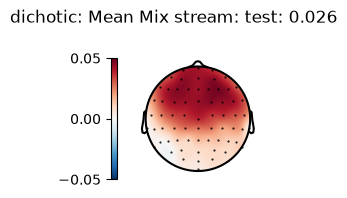

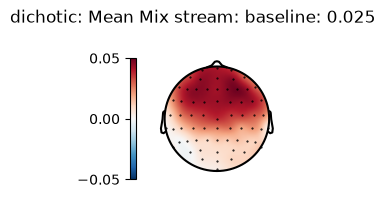

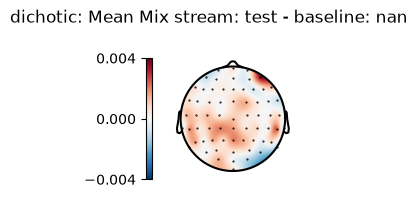

In [13]:
# Mix stream (envelope + onsets) unique contribution (dichotic)
data, diff, result = compute_direct_comparison(FULL_BASE, FULL_BASE_NO_MIX_STREAM, 'dichotic')
show_topomap_trio(data, diff, result, 'Mix stream', 'dichotic', None)

In [14]:
display(result)
print(f"Mix stream (dichotic): TFCE {tfce_summary(result)}")
ttest = test.TTestOneSample(f'roi_{METRIC}', data=diff, tail=1)
print(f"Mix stream (dichotic): ROI model comparison t({ttest.df}) = {ttest.t:.3f}, p = {ttest.p:.4f}")

<TTestRelated 'r', 'model', 'test', 'baseline', 'subject' (n=13), tail=1, samples=8191, tfce=True, p = .330>

Mix stream (dichotic): TFCE t_max = 1.63, p = 0.330
Mix stream (dichotic): ROI model comparison t(12) = 0.241, p = 0.4068


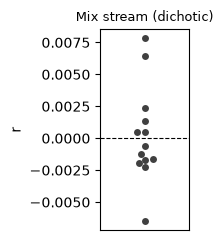

In [15]:
p = show_subject_swarm(diff, 'Mix stream', 'dichotic')

Permutation test:   0%|          | 0/8191 [00:00<?, ? permutations/s]

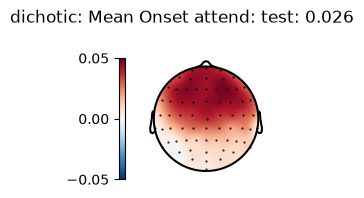

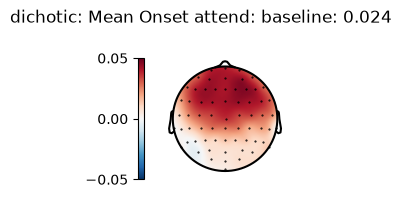

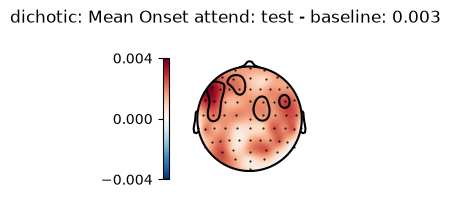

In [16]:
# Onset attend unique contribution (dichotic)
# Brodbeck et al. 2020 ran this comparison too: attended onsets unique contribution, t = 6.32, p < .001.
data, diff, result = compute_unique_contribution(FULL_BASE, onset(ATTEND), 'dichotic')
show_topomap_trio(data, diff, result, 'Onset attend', 'dichotic', onset(ATTEND))

In [17]:
display(result)
print(f"Onset attend (dichotic): TFCE {tfce_summary(result)}")
ttest = test.TTestOneSample(f'roi_{METRIC}', data=diff, tail=1)
print(f"Onset attend (dichotic): ROI unique contribution t({ttest.df}) = {ttest.t:.3f}, p = {ttest.p:.4f}")

<TTestRelated 'r', 'model', 'test', 'baseline', 'subject' (n=13), tail=1, samples=8191, tfce=True, p = .005>

Onset attend (dichotic): TFCE t_max = 3.64, p = 0.005
Onset attend (dichotic): ROI unique contribution t(12) = 2.855, p = 0.0072


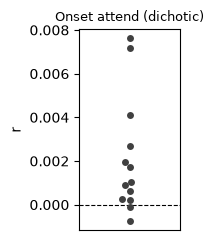

In [18]:
p = show_subject_swarm(diff, 'Onset attend', 'dichotic')

Permutation test:   0%|          | 0/8191 [00:00<?, ? permutations/s]

/Users/joshuaighalo/Github Repositories/cocktail-cortical/analysis/experiment.py:1063: UserWarning: Warning: converting a masked element to nan.
  mean_value = float(data.mean())


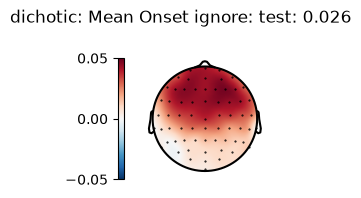

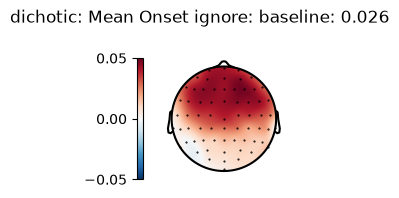

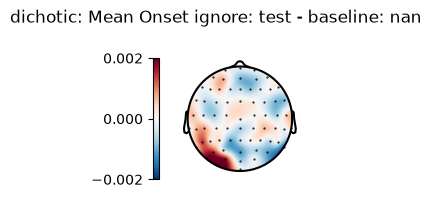

In [19]:
# Onset ignore unique contribution (dichotic)
# Brodbeck et al. 2020 ran this comparison too: ignored onsets unique contribution, t = 6.70, p < .001 - the ignored speaker is tracked separately.
data, diff, result = compute_unique_contribution(FULL_BASE, onset(IGNORE), 'dichotic')
show_topomap_trio(data, diff, result, 'Onset ignore', 'dichotic', onset(IGNORE))

In [20]:
display(result)
print(f"Onset ignore (dichotic): TFCE {tfce_summary(result)}")
ttest = test.TTestOneSample(f'roi_{METRIC}', data=diff, tail=1)
print(f"Onset ignore (dichotic): ROI unique contribution t({ttest.df}) = {ttest.t:.3f}, p = {ttest.p:.4f}")

<TTestRelated 'r', 'model', 'test', 'baseline', 'subject' (n=13), tail=1, samples=8191, tfce=True, p = .479>

Onset ignore (dichotic): TFCE t_max = 1.50, p = 0.479
Onset ignore (dichotic): ROI unique contribution t(12) = -0.737, p = 0.7624


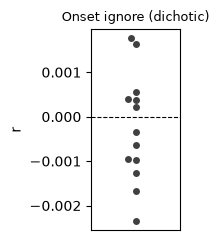

In [21]:
p = show_subject_swarm(diff, 'Onset ignore', 'dichotic')

Permutation test:   0%|          | 0/8191 [00:00<?, ? permutations/s]

/Users/joshuaighalo/Github Repositories/cocktail-cortical/analysis/experiment.py:1063: UserWarning: Warning: converting a masked element to nan.
  mean_value = float(data.mean())


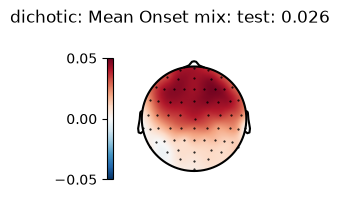

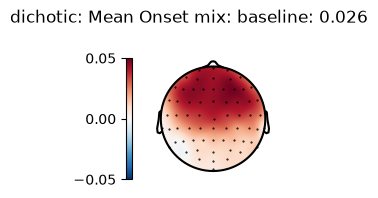

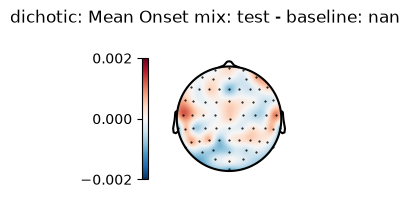

In [22]:
# Onset mix unique contribution (dichotic)
# Brodbeck et al. 2020 ran this comparison too: mixture onsets unique contribution, t = 8.61, p < .001.
data, diff, result = compute_unique_contribution(FULL_BASE, onset(MIX), 'dichotic')
show_topomap_trio(data, diff, result, 'Onset mix', 'dichotic', onset(MIX))

In [23]:
display(result)
print(f"Onset mix (dichotic): TFCE {tfce_summary(result)}")
ttest = test.TTestOneSample(f'roi_{METRIC}', data=diff, tail=1)
print(f"Onset mix (dichotic): ROI unique contribution t({ttest.df}) = {ttest.t:.3f}, p = {ttest.p:.4f}")

<TTestRelated 'r', 'model', 'test', 'baseline', 'subject' (n=13), tail=1, samples=8191, tfce=True, p = .542>

Onset mix (dichotic): TFCE t_max = 1.61, p = 0.542
Onset mix (dichotic): ROI unique contribution t(12) = 0.102, p = 0.4601


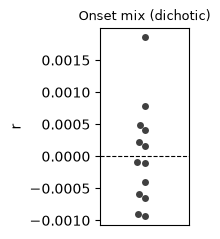

In [24]:
p = show_subject_swarm(diff, 'Onset mix', 'dichotic')

Permutation test:   0%|          | 0/8191 [00:00<?, ? permutations/s]

/Users/joshuaighalo/Github Repositories/cocktail-cortical/analysis/experiment.py:1063: UserWarning: Warning: converting a masked element to nan.
  mean_value = float(data.mean())


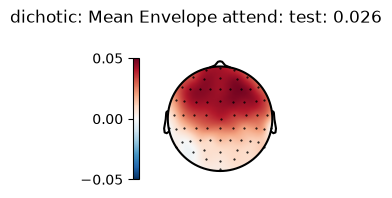

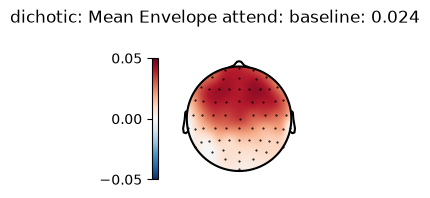

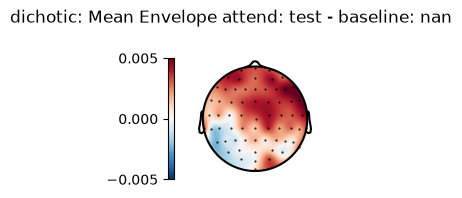

In [25]:
# Envelope attend unique contribution (dichotic)
# Brodbeck et al. 2020 ran this comparison too: attended envelope unique contribution, t = 7.37, p < .001.
data, diff, result = compute_unique_contribution(FULL_BASE, envelope(ATTEND), 'dichotic')
show_topomap_trio(data, diff, result, 'Envelope attend', 'dichotic', envelope(ATTEND))

In [26]:
display(result)
print(f"Envelope attend (dichotic): TFCE {tfce_summary(result)}")
ttest = test.TTestOneSample(f'roi_{METRIC}', data=diff, tail=1)
print(f"Envelope attend (dichotic): ROI unique contribution t({ttest.df}) = {ttest.t:.3f}, p = {ttest.p:.4f}")

<TTestRelated 'r', 'model', 'test', 'baseline', 'subject' (n=13), tail=1, samples=8191, tfce=True, p = .093>

Envelope attend (dichotic): TFCE t_max = 2.28, p = 0.093
Envelope attend (dichotic): ROI unique contribution t(12) = 1.611, p = 0.0665


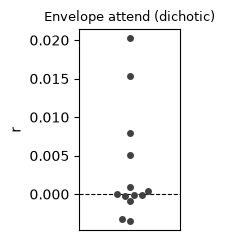

In [27]:
p = show_subject_swarm(diff, 'Envelope attend', 'dichotic')

Permutation test:   0%|          | 0/8191 [00:00<?, ? permutations/s]

/Users/joshuaighalo/Github Repositories/cocktail-cortical/analysis/experiment.py:1063: UserWarning: Warning: converting a masked element to nan.
  mean_value = float(data.mean())


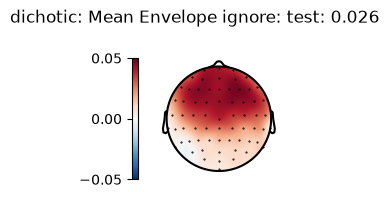

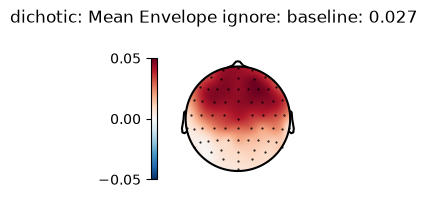

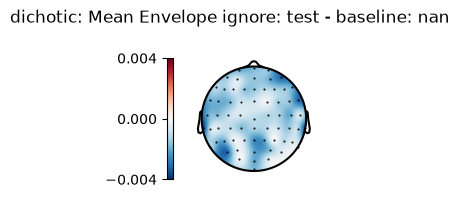

In [28]:
# Envelope ignore unique contribution (dichotic)
# Brodbeck et al. 2020 ran this comparison too: ignored envelope unique contribution, t = 6.28, p < .001 - the ignored speaker's envelope is tracked separately too.
data, diff, result = compute_unique_contribution(FULL_BASE, envelope(IGNORE), 'dichotic')
show_topomap_trio(data, diff, result, 'Envelope ignore', 'dichotic', envelope(IGNORE))

In [29]:
display(result)
print(f"Envelope ignore (dichotic): TFCE {tfce_summary(result)}")
ttest = test.TTestOneSample(f'roi_{METRIC}', data=diff, tail=1)
print(f"Envelope ignore (dichotic): ROI unique contribution t({ttest.df}) = {ttest.t:.3f}, p = {ttest.p:.4f}")

<TTestRelated 'r', 'model', 'test', 'baseline', 'subject' (n=13), tail=1, samples=8191, tfce=True, p = 1.000>

Envelope ignore (dichotic): TFCE t_max = -0.22, p = 1.000
Envelope ignore (dichotic): ROI unique contribution t(12) = -2.813, p = 0.9922


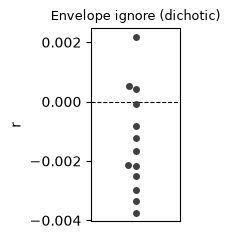

In [30]:
p = show_subject_swarm(diff, 'Envelope ignore', 'dichotic')

Permutation test:   0%|          | 0/8191 [00:00<?, ? permutations/s]

/Users/joshuaighalo/Github Repositories/cocktail-cortical/analysis/experiment.py:1063: UserWarning: Warning: converting a masked element to nan.
  mean_value = float(data.mean())


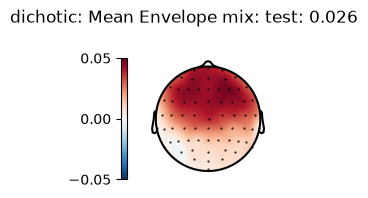

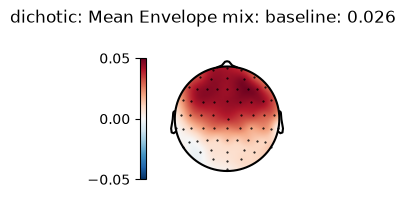

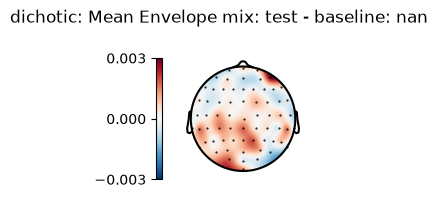

In [31]:
# Envelope mix unique contribution (dichotic)
# Brodbeck et al. 2020 ran this comparison too: mixture envelope unique contribution, t = 5.70, p < .001.
data, diff, result = compute_unique_contribution(FULL_BASE, envelope(MIX), 'dichotic')
show_topomap_trio(data, diff, result, 'Envelope mix', 'dichotic', envelope(MIX))

In [32]:
display(result)
print(f"Envelope mix (dichotic): TFCE {tfce_summary(result)}")
ttest = test.TTestOneSample(f'roi_{METRIC}', data=diff, tail=1)
print(f"Envelope mix (dichotic): ROI unique contribution t({ttest.df}) = {ttest.t:.3f}, p = {ttest.p:.4f}")

<TTestRelated 'r', 'model', 'test', 'baseline', 'subject' (n=13), tail=1, samples=8191, tfce=True, p = .576>

Envelope mix (dichotic): TFCE t_max = 0.99, p = 0.576
Envelope mix (dichotic): ROI unique contribution t(12) = -0.078, p = 0.5305


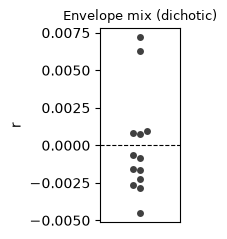

In [33]:
p = show_subject_swarm(diff, 'Envelope mix', 'dichotic')

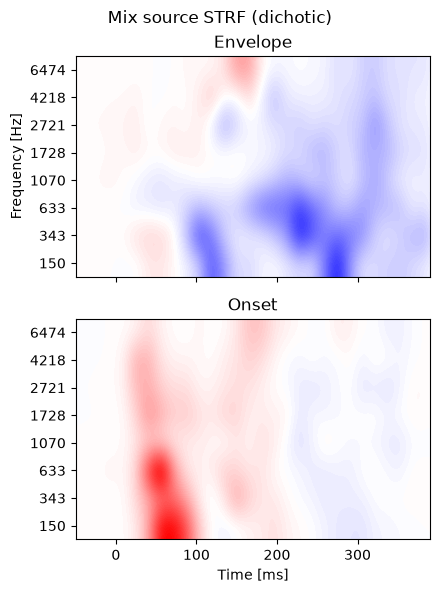

In [34]:
# Mix source STRF: envelope + onset (dichotic)
envelope_strf = extract_strf(data_full, 'mix_gammatone_8')
onset_strf = extract_strf(data_full, 'mix_gammatone_on_8')
p = plot.Array([envelope_strf * 1e3, onset_strf * 1e3], axtitle=['Envelope', 'Onset'],
                title='Mix source STRF (dichotic)', interpolation=STRF_INTERPOLATION, xlim=PLOT_WINDOW)

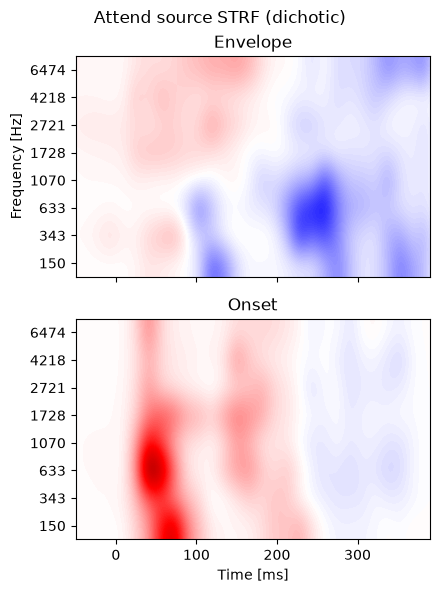

In [35]:
# Attend source STRF: envelope + onset (dichotic)
envelope_strf = extract_strf(data_full, 'gammatone_8')
onset_strf = extract_strf(data_full, 'gammatone_on_8')
p = plot.Array([envelope_strf * 1e3, onset_strf * 1e3], axtitle=['Envelope', 'Onset'],
                title='Attend source STRF (dichotic)', interpolation=STRF_INTERPOLATION, xlim=PLOT_WINDOW)

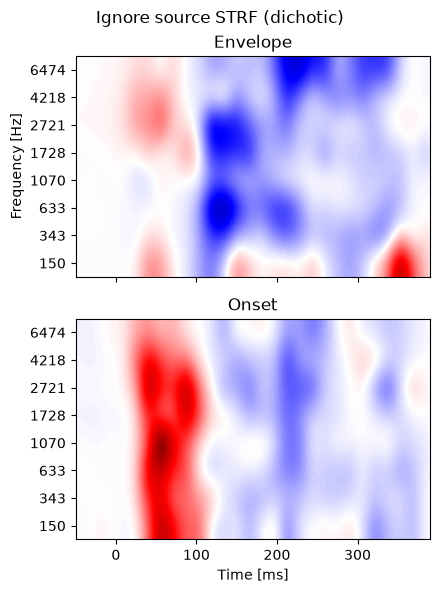

In [36]:
# Ignore source STRF: envelope + onset (dichotic)
envelope_strf = extract_strf(data_full, 'bg_gammatone_8')
onset_strf = extract_strf(data_full, 'bg_gammatone_on_8')
p = plot.Array([envelope_strf * 1e3, onset_strf * 1e3], axtitle=['Envelope', 'Onset'],
                title='Ignore source STRF (dichotic)', interpolation=STRF_INTERPOLATION, xlim=PLOT_WINDOW)

In [37]:
# Onset attend peak amplitude & timing (dichotic)
data = extract_trf(data_full, 'gammatone_on_8')
data = add_anchored_peak(data, 'positive', ONSET_POSITIVE_PEAK_WINDOW, kind='max')
data = add_anchored_peak(data, 'negative', ONSET_NEGATIVE_PEAK_WINDOW, kind='min')
print(f"Onset attend (dichotic) positive peak: {data['positive_time'].mean() * 1e3:.0f} ms, amp {data['positive_amp'].mean():.4g}")
print(f"Onset attend (dichotic) negative peak: {data['negative_time'].mean() * 1e3:.0f} ms, amp {data['negative_amp'].mean():.4g}")

Onset attend (dichotic) positive peak: 52 ms, amp 0.00533
Onset attend (dichotic) negative peak: 118 ms, amp -0.000193


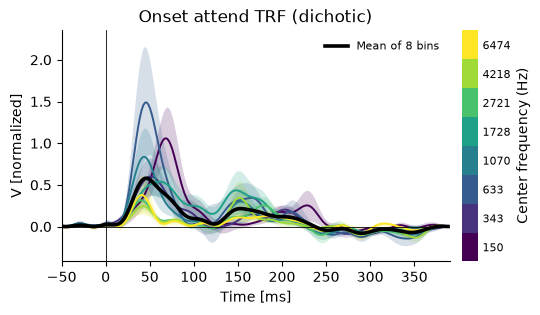

In [38]:
# Onset attend TRF per frequency bin (dichotic)
p = plot_trf_bins(data_full, 'gammatone_on_8', 'Onset attend TRF (dichotic)')

In [39]:
# Onset ignore peak amplitude & timing (dichotic)
data = extract_trf(data_full, 'bg_gammatone_on_8')
data = add_anchored_peak(data, 'positive', ONSET_POSITIVE_PEAK_WINDOW, kind='max')
data = add_anchored_peak(data, 'negative', ONSET_NEGATIVE_PEAK_WINDOW, kind='min')
print(f"Onset ignore (dichotic) positive peak: {data['positive_time'].mean() * 1e3:.0f} ms, amp {data['positive_amp'].mean():.4g}")
print(f"Onset ignore (dichotic) negative peak: {data['negative_time'].mean() * 1e3:.0f} ms, amp {data['negative_amp'].mean():.4g}")

Onset ignore (dichotic) positive peak: 53 ms, amp 0.002144
Onset ignore (dichotic) negative peak: 172 ms, amp -0.0005549


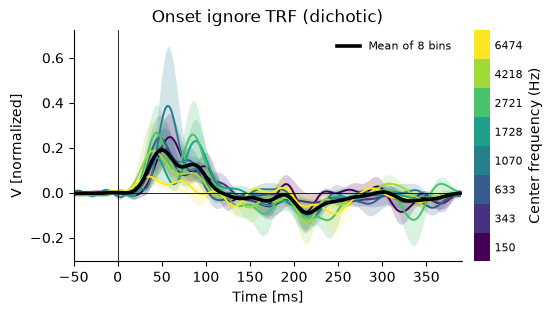

In [40]:
# Onset ignore TRF per frequency bin (dichotic)
p = plot_trf_bins(data_full, 'bg_gammatone_on_8', 'Onset ignore TRF (dichotic)')

In [41]:
# Onset mix peak amplitude & timing (dichotic)
data = extract_trf(data_full, 'mix_gammatone_on_8')
data = add_anchored_peak(data, 'positive', ONSET_POSITIVE_PEAK_WINDOW, kind='max')
data = add_anchored_peak(data, 'negative', ONSET_NEGATIVE_PEAK_WINDOW, kind='min')
print(f"Onset mix (dichotic) positive peak: {data['positive_time'].mean() * 1e3:.0f} ms, amp {data['positive_amp'].mean():.4g}")
print(f"Onset mix (dichotic) negative peak: {data['negative_time'].mean() * 1e3:.0f} ms, amp {data['negative_amp'].mean():.4g}")

Onset mix (dichotic) positive peak: 54 ms, amp 0.003551
Onset mix (dichotic) negative peak: 123 ms, amp -0.0001636


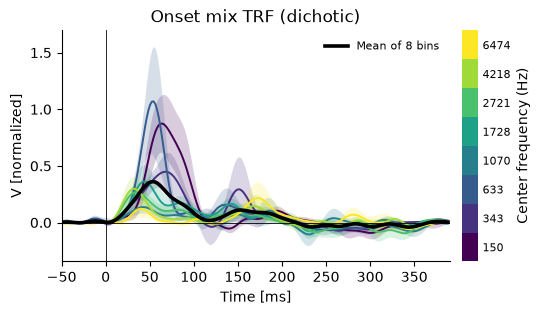

In [42]:
# Onset mix TRF per frequency bin (dichotic)
p = plot_trf_bins(data_full, 'mix_gammatone_on_8', 'Onset mix TRF (dichotic)')

In [43]:
# Envelope attend peak amplitude & timing (dichotic)
data = extract_trf(data_full, 'gammatone_8')
data = add_anchored_peak(data, 'positive', ENVELOPE_POSITIVE_PEAK_WINDOW, kind='max')
data = add_anchored_peak(data, 'negative', ENVELOPE_NEGATIVE_PEAK_WINDOW, kind='min')
print(f"Envelope attend (dichotic) positive peak: {data['positive_time'].mean() * 1e3:.0f} ms, amp {data['positive_amp'].mean():.4g}")
print(f"Envelope attend (dichotic) negative peak: {data['negative_time'].mean() * 1e3:.0f} ms, amp {data['negative_amp'].mean():.4g}")

Envelope attend (dichotic) positive peak: 53 ms, amp 0.001279
Envelope attend (dichotic) negative peak: 190 ms, amp -0.0004415


/Users/joshuaighalo/Github Repositories/cocktail-cortical/analysis/experiment.py:2361: UserWarning: negative anchor (all) at 199 ms is on the edge of the search window (0.02, 0.2)
  warnings.warn(f"{name} anchor ({label}) at {times[i] * 1e3:.0f} ms is on the edge of the search window {window}")


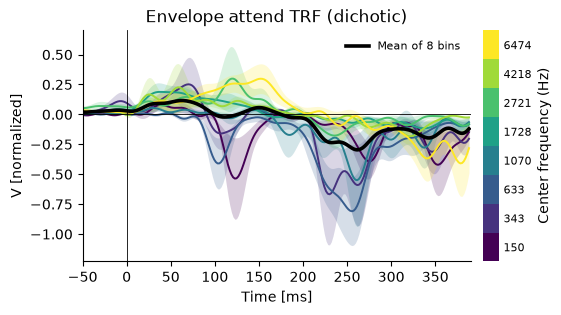

In [44]:
# Envelope attend TRF per frequency bin (dichotic)
p = plot_trf_bins(data_full, 'gammatone_8', 'Envelope attend TRF (dichotic)')

In [45]:
# Envelope ignore peak amplitude & timing (dichotic)
data = extract_trf(data_full, 'bg_gammatone_8')
data = add_anchored_peak(data, 'positive', ENVELOPE_POSITIVE_PEAK_WINDOW, kind='max')
data = add_anchored_peak(data, 'negative', ENVELOPE_NEGATIVE_PEAK_WINDOW, kind='min')
print(f"Envelope ignore (dichotic) positive peak: {data['positive_time'].mean() * 1e3:.0f} ms, amp {data['positive_amp'].mean():.4g}")
print(f"Envelope ignore (dichotic) negative peak: {data['negative_time'].mean() * 1e3:.0f} ms, amp {data['negative_amp'].mean():.4g}")

Envelope ignore (dichotic) positive peak: 46 ms, amp 0.0005328
Envelope ignore (dichotic) negative peak: 131 ms, amp -0.001453


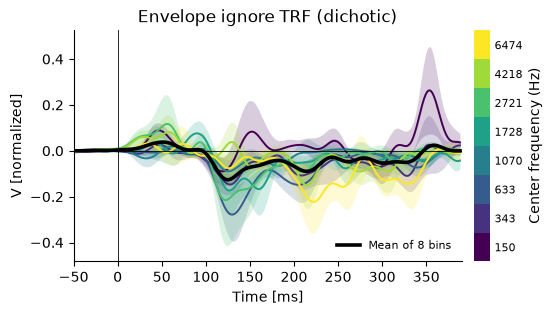

In [46]:
# Envelope ignore TRF per frequency bin (dichotic)
p = plot_trf_bins(data_full, 'bg_gammatone_8', 'Envelope ignore TRF (dichotic)')

In [47]:
# Envelope mix peak amplitude & timing (dichotic)
data = extract_trf(data_full, 'mix_gammatone_8')
data = add_anchored_peak(data, 'positive', ENVELOPE_POSITIVE_PEAK_WINDOW, kind='max')
data = add_anchored_peak(data, 'negative', ENVELOPE_NEGATIVE_PEAK_WINDOW, kind='min')
print(f"Envelope mix (dichotic) positive peak: {data['positive_time'].mean() * 1e3:.0f} ms, amp {data['positive_amp'].mean():.4g}")
print(f"Envelope mix (dichotic) negative peak: {data['negative_time'].mean() * 1e3:.0f} ms, amp {data['negative_amp'].mean():.4g}")

Envelope mix (dichotic) positive peak: 34 ms, amp 0.0004084
Envelope mix (dichotic) negative peak: 193 ms, amp -0.00145


/Users/joshuaighalo/Github Repositories/cocktail-cortical/analysis/experiment.py:2361: UserWarning: negative anchor (all) at 199 ms is on the edge of the search window (0.02, 0.2)
  warnings.warn(f"{name} anchor ({label}) at {times[i] * 1e3:.0f} ms is on the edge of the search window {window}")


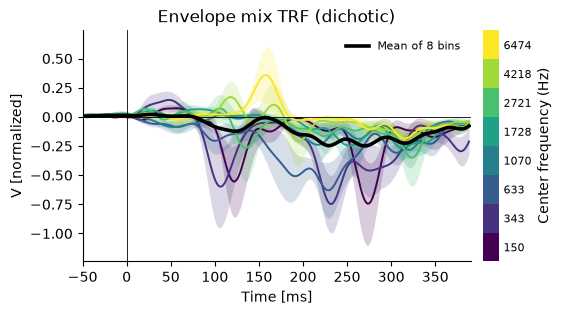

In [48]:
# Envelope mix TRF per frequency bin (dichotic)
p = plot_trf_bins(data_full, 'mix_gammatone_8', 'Envelope mix TRF (dichotic)')

In [49]:
# Onset peak comparison across mix, attend, and ignore (dichotic)
# Brodbeck et al. 2020 ran this comparison too: positive peak latency mixture 72ms, attended 81ms (t=4.47,p<.001), ignored 89ms (t=6.92,p<.001); negative peak latency mixture 138ms, attended 150ms (t=3.20,p=.004); positive peak amplitude bigger for mixture than attended (t=8.41) or ignored (t=7.66).
dss = []
for role_name, column in (('mix', 'mix_gammatone_on_8'), ('attend', 'gammatone_on_8'), ('ignore', 'bg_gammatone_on_8')):
    ds = extract_trf(data_full, column)
    ds[:, 'role'] = role_name
    dss.append(ds)
data = combine(dss)
data = add_anchored_peak(data, 'positive', ONSET_POSITIVE_PEAK_WINDOW, kind='max', by='role')
data = add_anchored_peak(data, 'negative', ONSET_NEGATIVE_PEAK_WINDOW, kind='min', by='role')

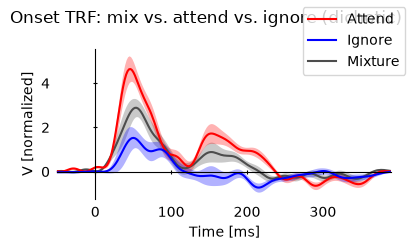

In [50]:
# The onset TRF waveform mix/attend/ignore were each just measured
# from, overlaid so their shape and relative timing are visible
# directly, not just as extracted peak numbers below.
p = plot.UTSStat('trf_sm*1e3', 'role', data=data, match='subject', within_subject_error=True, frame='t', h=2.5, w=4, xlim=PLOT_WINDOW,
                  title='Onset TRF: mix vs. attend vs. ignore (dichotic)', labels=LABELS_ROLE, colors=COLORS_ROLE)

In [51]:
print_peak_table(data, 'positive', 'role')
print_peak_table(data, 'negative', 'role')


positive peak
subject   role         time (ms)           amp
01        mix                 58      0.001199
02        mix                 66      0.003146
03        mix                 41      0.002217
04        mix                 56      0.001707
05        mix                 50      0.003542
06        mix                 35      0.002131
07        mix                 78      0.003873
08        mix                 48      0.006761
09        mix                 60       0.00464
10        mix                 58      0.009313
11        mix                 66      0.004566
12        mix                 31      0.002636
13        mix                 58     0.0004275
01        attend              62      0.001015
02        attend              54      0.004922
03        attend              50      0.000796
04        attend              46       0.00164
05        attend              41       0.01659
06        attend              46      0.002991
07        attend              62      0.00431

In [52]:
display(test.pairwise('positive_time', 'role', match='subject', data=data, corr=False, title='onset positive peak latency: mix vs. attend vs. ignore'))
display(test.pairwise('negative_time', 'role', match='subject', data=data, corr=False, title='onset negative peak latency: mix vs. attend vs. ignore'))

,attend,ignore
mix,t12 = 0.65 p = .528,t12 = 0.23 p = .820
attend,,t12 = -0.33 p = .749


,attend,ignore
mix,t12 = 1.07 p = .308,t12 = -7.19*** p < .001
attend,,t12 = -8.79*** p < .001


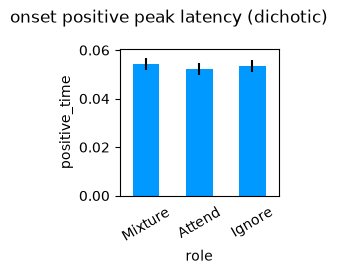

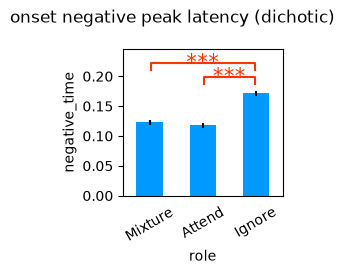

In [53]:
p = plot.Barplot('positive_time', 'role', match='subject', data=data, h=2.5, w=2.5, labels=LABELS_ROLE, corr=False, title='onset positive peak latency (dichotic)')
p.set_xtick_rotation(30)
p = plot.Barplot('negative_time', 'role', match='subject', data=data, h=2.5, w=2.5, labels=LABELS_ROLE, corr=False, title='onset negative peak latency (dichotic)')
p.set_xtick_rotation(30)

In [54]:
display(test.pairwise('positive_amp', 'role', match='subject', data=data, corr=False, title='onset positive peak amplitude: mix vs. attend vs. ignore'))
display(test.pairwise('negative_amp', 'role', match='subject', data=data, corr=False, title='onset negative peak amplitude: mix vs. attend vs. ignore'))

,attend,ignore
mix,t12 = -1.60 p = .136,t12 = 2.16 p = .052
attend,,t12 = 3.07** p = .010


,attend,ignore
mix,t12 = 0.10 p = .923,t12 = 2.39* p = .034
attend,,t12 = 1.11 p = .289


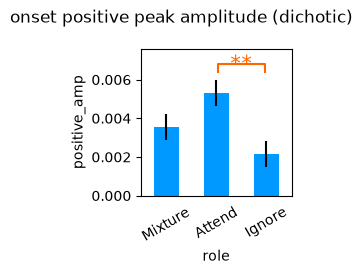

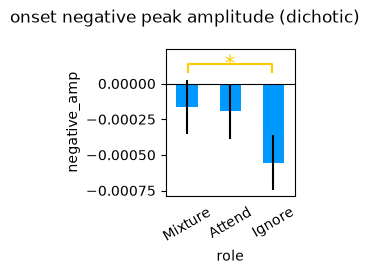

In [55]:
p = plot.Barplot('positive_amp', 'role', match='subject', data=data, h=2.5, w=2.5, labels=LABELS_ROLE, corr=False, title='onset positive peak amplitude (dichotic)')
p.set_xtick_rotation(30)
p = plot.Barplot('negative_amp', 'role', match='subject', data=data, h=2.5, w=2.5, labels=LABELS_ROLE, corr=False, title='onset negative peak amplitude (dichotic)')
p.set_xtick_rotation(30)

In [56]:
# Envelope peak comparison across mix, attend, and ignore (dichotic)
dss = []
for role_name, column in (('mix', 'mix_gammatone_8'), ('attend', 'gammatone_8'), ('ignore', 'bg_gammatone_8')):
    ds = extract_trf(data_full, column)
    ds[:, 'role'] = role_name
    dss.append(ds)
data = combine(dss)
data = add_anchored_peak(data, 'positive', ENVELOPE_POSITIVE_PEAK_WINDOW, kind='max', by='role')
data = add_anchored_peak(data, 'negative', ENVELOPE_NEGATIVE_PEAK_WINDOW, kind='min', by='role')

/Users/joshuaighalo/Github Repositories/cocktail-cortical/analysis/experiment.py:2361: UserWarning: negative anchor (mix) at 199 ms is on the edge of the search window (0.02, 0.2)
  warnings.warn(f"{name} anchor ({label}) at {times[i] * 1e3:.0f} ms is on the edge of the search window {window}")
/Users/joshuaighalo/Github Repositories/cocktail-cortical/analysis/experiment.py:2361: UserWarning: negative anchor (attend) at 199 ms is on the edge of the search window (0.02, 0.2)
  warnings.warn(f"{name} anchor ({label}) at {times[i] * 1e3:.0f} ms is on the edge of the search window {window}")


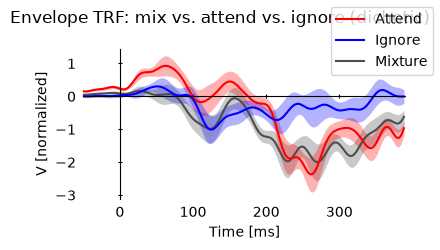

In [57]:
# The envelope TRF waveform mix/attend/ignore were each just measured
# from, overlaid so their shape and relative timing are visible
# directly, not just as extracted peak numbers below.
p = plot.UTSStat('trf_sm*1e3', 'role', data=data, match='subject', within_subject_error=True, frame='t', h=2.5, w=4, xlim=PLOT_WINDOW,
                  title='Envelope TRF: mix vs. attend vs. ignore (dichotic)', labels=LABELS_ROLE, colors=COLORS_ROLE)

In [58]:
print_peak_table(data, 'positive', 'role')
print_peak_table(data, 'negative', 'role')


positive peak
subject   role         time (ms)           amp
01        mix                 50      0.002149
02        mix                 33    -0.0001795
03        mix                 37     0.0007781
04        mix                 21     0.0001367
05        mix                 50    -0.0002976
06        mix                 21    -0.0002135
07        mix                 41     0.0001092
08        mix                 37      0.001292
09        mix                 50     0.0001187
10        mix                 31     0.0006023
11        mix                 23     0.0008862
12        mix                 21    -0.0001816
13        mix                 33       0.00011
01        attend              64      0.007251
02        attend              45     0.0002775
03        attend              56     0.0004109
04        attend              39     0.0003282
05        attend              76     0.0004293
06        attend              86      0.000757
07        attend              54      0.00154

In [59]:
display(test.pairwise('positive_time', 'role', match='subject', data=data, corr=False, title='envelope positive peak latency: mix vs. attend vs. ignore'))
display(test.pairwise('negative_time', 'role', match='subject', data=data, corr=False, title='envelope negative peak latency: mix vs. attend vs. ignore'))

,attend,ignore
mix,t12 = -4.34*** p < .001,t12 = -2.58* p = .024
attend,,t12 = 1.05 p = .316


,attend,ignore
mix,t12 = 0.85 p = .412,t12 = 11.52*** p < .001
attend,,t12 = 11.94*** p < .001


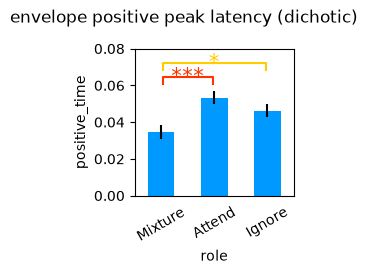

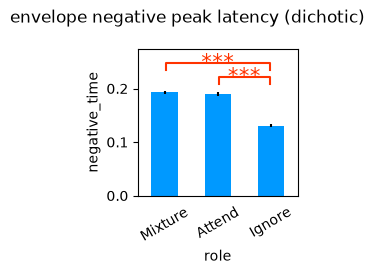

In [60]:
p = plot.Barplot('positive_time', 'role', match='subject', data=data, h=2.5, w=2.5, labels=LABELS_ROLE, corr=False, title='envelope positive peak latency (dichotic)')
p.set_xtick_rotation(30)
p = plot.Barplot('negative_time', 'role', match='subject', data=data, h=2.5, w=2.5, labels=LABELS_ROLE, corr=False, title='envelope negative peak latency (dichotic)')
p.set_xtick_rotation(30)

In [61]:
display(test.pairwise('positive_amp', 'role', match='subject', data=data, corr=False, title='envelope positive peak amplitude: mix vs. attend vs. ignore'))
display(test.pairwise('negative_amp', 'role', match='subject', data=data, corr=False, title='envelope negative peak amplitude: mix vs. attend vs. ignore'))

,attend,ignore
mix,t12 = -2.22* p = .046,t12 = -0.51 p = .617
attend,,t12 = 1.57 p = .143


,attend,ignore
mix,t12 = -4.20** p = .001,t12 = 0.01 p = .996
attend,,t12 = 2.43* p = .032


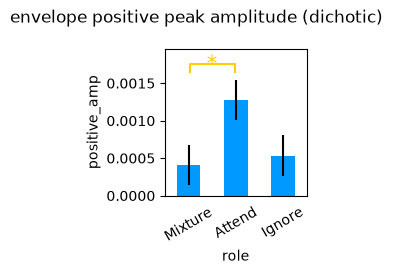

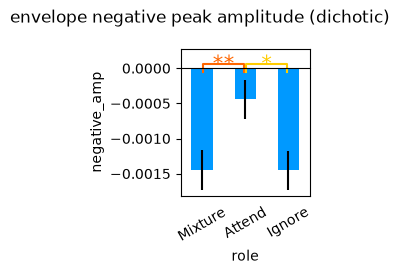

In [62]:
p = plot.Barplot('positive_amp', 'role', match='subject', data=data, h=2.5, w=2.5, labels=LABELS_ROLE, corr=False, title='envelope positive peak amplitude (dichotic)')
p.set_xtick_rotation(30)
p = plot.Barplot('negative_amp', 'role', match='subject', data=data, h=2.5, w=2.5, labels=LABELS_ROLE, corr=False, title='envelope negative peak amplitude (dichotic)')
p.set_xtick_rotation(30)

Permutation test:   0%|          | 0/8191 [00:00<?, ? permutations/s]

Envelope attention effect: attend - ignore (dichotic): bins that differ from 0 somewhere: none


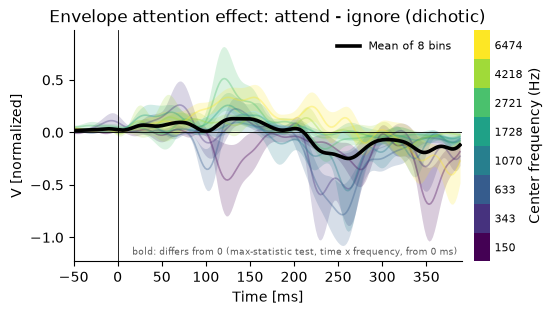

In [63]:
# Envelope attention effect: attend - ignore (dichotic)
# Brodbeck et al. 2020 ran this comparison too: envelope attention-effect difference wave: negative bump ~100ms, positive bump ~200ms, starting almost immediately.
p = plot_trf_bins(data_full, 'gammatone_8', 'Envelope attention effect: attend - ignore (dichotic)', subtract='bg_gammatone_8')

Permutation test:   0%|          | 0/8191 [00:00<?, ? permutations/s]

Envelope attention effect: attend - ignore (dichotic): no time range differs from 0 (max-statistic permutation test from 0 ms, two-tailed, smallest p = 0.068)


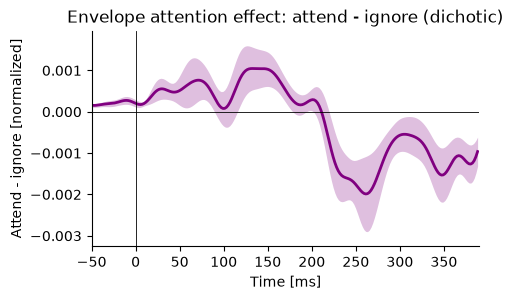

In [64]:
# The same attention effect as one waveform: summed over the frequency bins, mean +- 1 SEM across
# subjects; grey where attend - ignore differs from 0 (TFCE over time, two-tailed).
p = plot_attention_effect(data_full, 'gammatone_8', 'bg_gammatone_8', 'Envelope attention effect: attend - ignore (dichotic)')

Permutation test:   0%|          | 0/8191 [00:00<?, ? permutations/s]

Onset attention effect: attend - ignore (dichotic): bins that differ from 0 somewhere: none


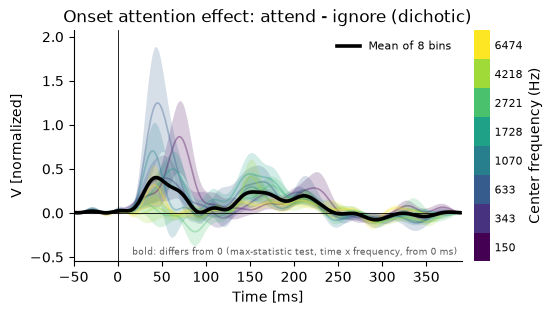

In [65]:
# Onset attention effect: attend - ignore (dichotic)
# Brodbeck et al. 2020 ran this comparison too: onset attention effect appears later than the envelope's, once the masked-onset response develops (see the masked-onset section below).
p = plot_trf_bins(data_full, 'gammatone_on_8', 'Onset attention effect: attend - ignore (dichotic)', subtract='bg_gammatone_on_8')

Permutation test:   0%|          | 0/8191 [00:00<?, ? permutations/s]

Onset attention effect: attend - ignore (dichotic): differs from 0 (max-statistic permutation test from 0 ms, two-tailed; ranges < 10 ms apart joined) at 48-68 ms (p = 0.002); 166-183 ms (p = 0.006); 195-220 ms (p = 0.005)


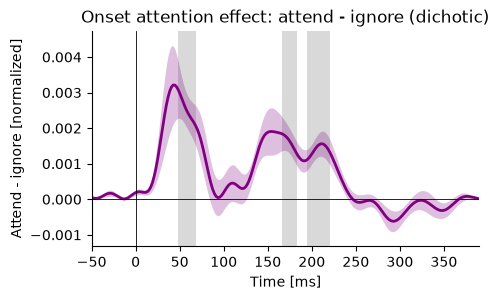

In [66]:
# The same attention effect as one waveform: summed over the frequency bins, mean +- 1 SEM across
# subjects; grey where attend - ignore differs from 0 (TFCE over time, two-tailed).
p = plot_attention_effect(data_full, 'gammatone_on_8', 'bg_gammatone_on_8', 'Onset attention effect: attend - ignore (dichotic)')